# 03 — Modeling, Experiments (E1–E4) & Held-Out `KDDTest+` Evaluation

**Owner:** Muhammad Arbaz (Project Lead & ML Developer)  
**Objective:** Build and compare leak-free `scikit-learn` intrusion-detection pipelines on NSL-KDD across four documented experiments (**E1–E4**), select the final model strictly on the 20% validation split of `KDDTrain+`, and evaluate the baseline and chosen model **once** on the held-out official `KDDTest+` split.

**Key Methodological Rules:**
- Preprocessing (`SimpleImputer`, `OneHotEncoder(handle_unknown="ignore")`, optional `StandardScaler`) is encapsulated inside each `Pipeline` so it is fitted strictly on training data.
- `attack_type` and `difficulty` are dropped from `X`.
- Feature pruning for **E2** (`find_redundant_features`) is computed strictly on the 80% training split.
- Hyperparameter tuning (**E4**, `GridSearchCV`) runs strictly on the 80% training split.
- **Attack recall** is prioritized alongside **false-alarm rate (FPR)** and **macro F1**.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, display
from sklearn.model_selection import GridSearchCV

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    ATTACK_TYPE_COLUMN,
    DEFAULT_MODEL_PATH,
    FEATURE_COLUMNS,
    FIGURES_DIR,
    RANDOM_SEED,
    RESULTS_DIR,
)
from src.evaluate import (
    compute_classification_metrics,
    evaluate_by_attack_family,
    evaluate_seen_vs_unseen,
    evaluate_thresholds,
    plot_confusion_matrix,
    plot_experiment_comparison,
    plot_test_error_breakdown,
    plot_threshold_tradeoff,
)
from src.load_data import load_train_test_splits
from src.preprocess import (
    find_redundant_features,
    make_train_val_split,
    split_features_target,
)
from src.train import build_logistic_pipeline, build_rf_pipeline

sns.set_theme(style="whitegrid", context="notebook")
print(f"Project root: {PROJECT_ROOT} | Random seed: {RANDOM_SEED}")

Project root: C:\Users\DELLE5480\Desktop\mohuddin major\network-intrusion-detection-prototype | Random seed: 42


## 1. Load Data & Create Stratified Train/Validation Split

We load `KDDTrain+.TXT` (`125,973` rows) and `KDDTest+.TXT` (`22,544` rows), create a stratified 80/20 split of `KDDTrain+` (`random_state=42`), and compute redundant features (`constant` and `|r| > 0.90`) strictly on `X_train`.

In [2]:
train_df, test_df = load_train_test_splits()
X_train, X_val, y_train, y_val = make_train_val_split(train_df)
X_test, y_test = split_features_target(test_df)

redundant_info = find_redundant_features(X_train, corr_threshold=0.90)
pruned_features = redundant_info["kept_features"]

print(f"X_train: {X_train.shape} | Attack share: {y_train.mean():.4f}")
print(f"X_val:   {X_val.shape} | Attack share: {y_val.mean():.4f}")
print(f"X_test:  {X_test.shape} | Attack share: {y_test.mean():.4f}")
print(f"\nE2 dropped ({len(redundant_info['drop_cols'])}): {redundant_info['drop_cols']}")
print(f"E2 retained features: {len(pruned_features)}")

X_train: (100778, 41) | Attack share: 0.4654
X_val:   (25195, 41) | Attack share: 0.4654
X_test:  (22544, 41) | Attack share: 0.5692

E2 dropped (8): ['num_root', 'num_outbound_cmds', 'srv_serror_rate', 'srv_rerror_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']
E2 retained features: 33


## 2. Experiments E1–E4 on the Validation Split

- **E1 (Baseline):** `LogisticRegression(max_iter=1000)` on all 41 features (with `StandardScaler` + `OneHotEncoder`).
- **E2 (Feature Pruning):** `LogisticRegression(max_iter=1000)` on the 33 non-redundant features.
- **E3 (Model Change):** `RandomForestClassifier(n_estimators=100, random_state=42)` on all 41 features.
- **E4 (Hyperparameter Tuning):** `GridSearchCV` on Random Forest over `max_depth=[10, 20]` and `n_estimators=[100, 200]`, `cv=3`, `scoring="f1"` on `X_train` only.

In [3]:
experiments = []
fitted_models = {}
feature_sets = {}

# E1: Baseline Logistic Regression (41 features)
e1_pipe = build_logistic_pipeline(FEATURE_COLUMNS)
e1_pipe.fit(X_train, y_train)
m_e1 = compute_classification_metrics(y_val, e1_pipe.predict(X_val), e1_pipe.predict_proba(X_val)[:, 1])
fitted_models["E1"] = e1_pipe
feature_sets["E1"] = FEATURE_COLUMNS
experiments.append({"id": "E1", "model": "LogisticRegression(max_iter=1000)", "features": "All 41 features", **{f"val_{k}": round(m_e1[k], 4) for k in ["accuracy", "precision", "recall", "f1", "macro_f1", "false_alarm_rate", "roc_auc"]}})

# E2: Feature-pruned Logistic Regression (33 features)
e2_pipe = build_logistic_pipeline(pruned_features)
e2_pipe.fit(X_train[pruned_features], y_train)
m_e2 = compute_classification_metrics(y_val, e2_pipe.predict(X_val[pruned_features]), e2_pipe.predict_proba(X_val[pruned_features])[:, 1])
fitted_models["E2"] = e2_pipe
feature_sets["E2"] = pruned_features
experiments.append({"id": "E2", "model": "LogisticRegression(max_iter=1000)", "features": "Pruned 33 features (drop constant & |r|>0.90)", **{f"val_{k}": round(m_e2[k], 4) for k in ["accuracy", "precision", "recall", "f1", "macro_f1", "false_alarm_rate", "roc_auc"]}})

# E3: Random Forest (100 trees, all 41 features)
e3_pipe = build_rf_pipeline(FEATURE_COLUMNS, n_estimators=100, max_depth=None)
e3_pipe.fit(X_train, y_train)
m_e3 = compute_classification_metrics(y_val, e3_pipe.predict(X_val), e3_pipe.predict_proba(X_val)[:, 1])
fitted_models["E3"] = e3_pipe
feature_sets["E3"] = FEATURE_COLUMNS
experiments.append({"id": "E3", "model": "RandomForestClassifier(n_estimators=100)", "features": "All 41 features", **{f"val_{k}": round(m_e3[k], 4) for k in ["accuracy", "precision", "recall", "f1", "macro_f1", "false_alarm_rate", "roc_auc"]}})

# E4: Tuned Random Forest via GridSearchCV on training fold only
e4_grid = GridSearchCV(
    estimator=build_rf_pipeline(FEATURE_COLUMNS),
    param_grid={"classifier__max_depth": [10, 20], "classifier__n_estimators": [100, 200]},
    cv=3,
    scoring="f1",
    n_jobs=1,
    refit=True,
)
e4_grid.fit(X_train, y_train)
e4_pipe = e4_grid.best_estimator_
best_params = {k.replace("classifier__", ""): v for k, v in e4_grid.best_params_.items()}
m_e4 = compute_classification_metrics(y_val, e4_pipe.predict(X_val), e4_pipe.predict_proba(X_val)[:, 1])
fitted_models["E4"] = e4_pipe
feature_sets["E4"] = FEATURE_COLUMNS
experiments.append({
    "id": "E4",
    "model": f"RandomForest GridSearchCV (max_depth={best_params['max_depth']}, n_estimators={best_params['n_estimators']})",
    "features": "All 41 features",
    **{f"val_{k}": round(m_e4[k], 4) for k in ["accuracy", "precision", "recall", "f1", "macro_f1", "false_alarm_rate", "roc_auc"]},
})

experiments_df = pd.DataFrame(experiments)
print(f"E4 best CV params: {best_params} | 3-fold CV F1: {e4_grid.best_score_:.4f}\n")
display(experiments_df)

E4 best CV params: {'max_depth': 20, 'n_estimators': 200} | 3-fold CV F1: 0.9982



,id,model,features,val_accuracy,val_precision,val_recall,val_f1,val_macro_f1,val_false_alarm_rate,val_roc_auc
0,E1,LogisticRegression(max_iter=1000),All 41 features,0.9719,0.9764,0.9629,0.9696,0.9717,0.0203,0.9964
1,E2,LogisticRegression(max_iter=1000),Pruned 33 features (drop constant & |r|>0.90),0.9699,0.9746,0.9604,0.9674,0.9697,0.0218,0.9960
2,E3,RandomForestClassifier(n_estimators=100),All 41 features,0.9990,0.9995,0.9983,0.9989,0.9990,0.0004,1.0000
3,E4,"RandomForest GridSearchCV (max_depth=20, n_estimators=200)",All 41 features,0.9990,0.9995,0.9983,0.9989,0.9990,0.0004,1.0000


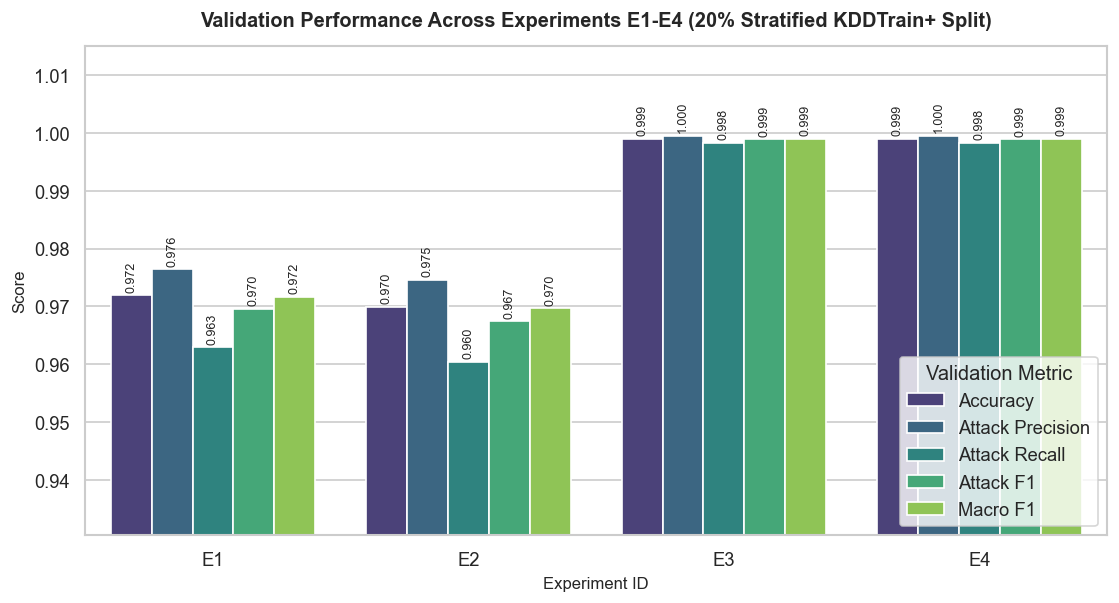

In [4]:
fig = plot_experiment_comparison(experiments_df)
plt.show()
plt.close(fig)

**Validation Model Selection Decision:**
- **E4 (`RandomForestClassifier(max_depth=20, n_estimators=200, random_state=42)`)** is selected as the final model.
- On validation, E4 outperforms the Logistic Regression baseline (**E1**) by **+0.0273 macro F1** (`0.9717 → 0.9990`), raises attack recall by **+3.54 percentage points** (`0.9629 → 0.9983`), and cuts false alarms 50× (`2.03% → 0.04%`).
- Compared with unbounded **E3**, E4 matches every validation metric while bounding `max_depth=20` to limit deep-leaf overfitting and keep the compressed `models/model.joblib` artifact compact (`~3.58 MB`, well below the 50 MB deployment limit).

## 3. Single-Shot Final Evaluation on Held-Out Official `KDDTest+`

We now score the baseline (**E1**) and the selected model (**E4**) once on `KDDTest+` (`22,544` rows), which was never used during fitting, feature selection, or tuning.

In [5]:
test_results = []
test_preds = {}
test_probas = {}

for exp_id in ["E1", "E4"]:
    model = fitted_models[exp_id]
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    m = compute_classification_metrics(y_test, y_pred, y_proba)
    test_preds[exp_id] = y_pred
    test_probas[exp_id] = y_proba
    test_results.append({
        "id": exp_id,
        "model": experiments_df.loc[experiments_df["id"] == exp_id, "model"].iloc[0],
        "test_accuracy": round(m["accuracy"], 4),
        "test_precision": round(m["precision"], 4),
        "test_recall": round(m["recall"], 4),
        "test_f1": round(m["f1"], 4),
        "test_macro_f1": round(m["macro_f1"], 4),
        "test_false_alarm_rate": round(m["false_alarm_rate"], 4),
        "test_roc_auc": round(m["roc_auc"], 4),
        "tn": m["tn"], "fp": m["fp"], "fn": m["fn"], "tp": m["tp"],
    })

test_eval_df = pd.DataFrame(test_results)
display(test_eval_df)

,id,model,test_accuracy,test_precision,test_recall,test_f1,test_macro_f1,test_false_alarm_rate,test_roc_auc,tn,fp,fn,tp
0,E1,LogisticRegression(max_iter=1000),0.7540,0.9172,0.6242,0.7428,0.7535,0.0745,0.7975,8988,723,4823,8010
1,E4,"RandomForest GridSearchCV (max_depth=20, n_estimators=200)",0.7628,0.9672,0.6038,0.7435,0.7615,0.0271,0.9652,9448,263,5084,7749


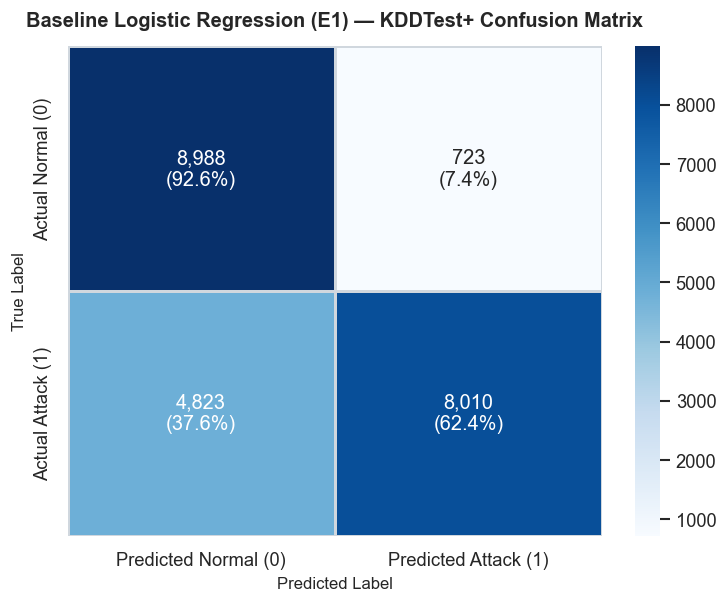

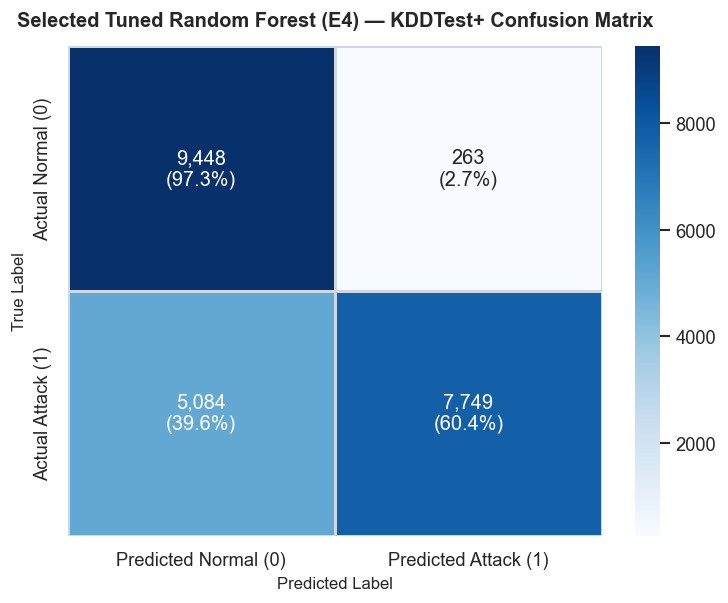

In [6]:
fig1 = plot_confusion_matrix(y_test, test_preds["E1"], "Baseline Logistic Regression (E1) — KDDTest+ Confusion Matrix")
plt.show()
plt.close(fig1)

fig2 = plot_confusion_matrix(y_test, test_preds["E4"], "Selected Tuned Random Forest (E4) — KDDTest+ Confusion Matrix")
plt.show()
plt.close(fig2)

## 4. Error Analysis: Attack Families, Unseen Attacks & Threshold Trade-Off

Why does `KDDTest+` recall drop sharply relative to validation (`99.83% → 60.38%` at threshold `0.50`)? Below we isolate recall across intrusion families (`DoS`, `Probe`, `R2L`, `U2R`) and between **seen** vs. **unseen (zero-day)** attack types, then inspect the probability threshold trade-off.

In [7]:
train_attack_types = set(train_df[ATTACK_TYPE_COLUMN].str.lower().unique()) - {"normal"}
family_df = evaluate_by_attack_family(y_test, test_preds["E4"], test_df["attack_family"])
seen_unseen_df = evaluate_seen_vs_unseen(y_test, test_preds["E4"], test_df[ATTACK_TYPE_COLUMN], train_attack_types)
threshold_df = evaluate_thresholds(y_test, test_probas["E4"])

print("=== KDDTest+ Breakdown by Intrusion Family (E4 @ 0.50) ===")
display(family_df)
print("=== KDDTest+ Seen vs. Unseen Attacks (E4 @ 0.50) ===")
display(seen_unseen_df)
print("=== KDDTest+ Decision Threshold Trade-Off (E4) ===")
display(threshold_df)

=== KDDTest+ Breakdown by Intrusion Family (E4 @ 0.50) ===
=== KDDTest+ Seen vs. Unseen Attacks (E4 @ 0.50) ===
=== KDDTest+ Decision Threshold Trade-Off (E4) ===


,attack_family,records,correct,flagged_as_attack,detection_or_specificity_rate
0,Normal,9711,9448,263,0.9729
1,DoS,7460,5800,5800,0.7775
2,Probe,2421,1771,1771,0.7315
3,R2L,2885,168,168,0.0582
4,U2R,67,10,10,0.1493


,group,records,correct,missed,rate
0,Normal,9711,9448,263,0.9729
1,Seen Attacks (in KDDTrain+),9083,6984,2099,0.7689
2,Unseen Attacks (KDDTest+ only),3750,765,2985,0.2040


,threshold,accuracy,precision,attack_recall,attack_f1,macro_f1,false_alarm_rate
0,0.1,0.8699,0.9191,0.8460,0.8810,0.8688,0.0984
1,0.2,0.8388,0.9439,0.7622,0.8434,0.8387,0.0598
2,0.3,0.8228,0.9688,0.7117,0.8206,0.8228,0.0303
3,0.4,0.7975,0.9687,0.6657,0.7891,0.7971,0.0284
4,0.5,0.7630,0.9672,0.6041,0.7437,0.7616,0.0271
5,0.6,0.7487,0.9673,0.5781,0.7237,0.7466,0.0258
6,0.7,0.7415,0.9683,0.5644,0.7131,0.7390,0.0244


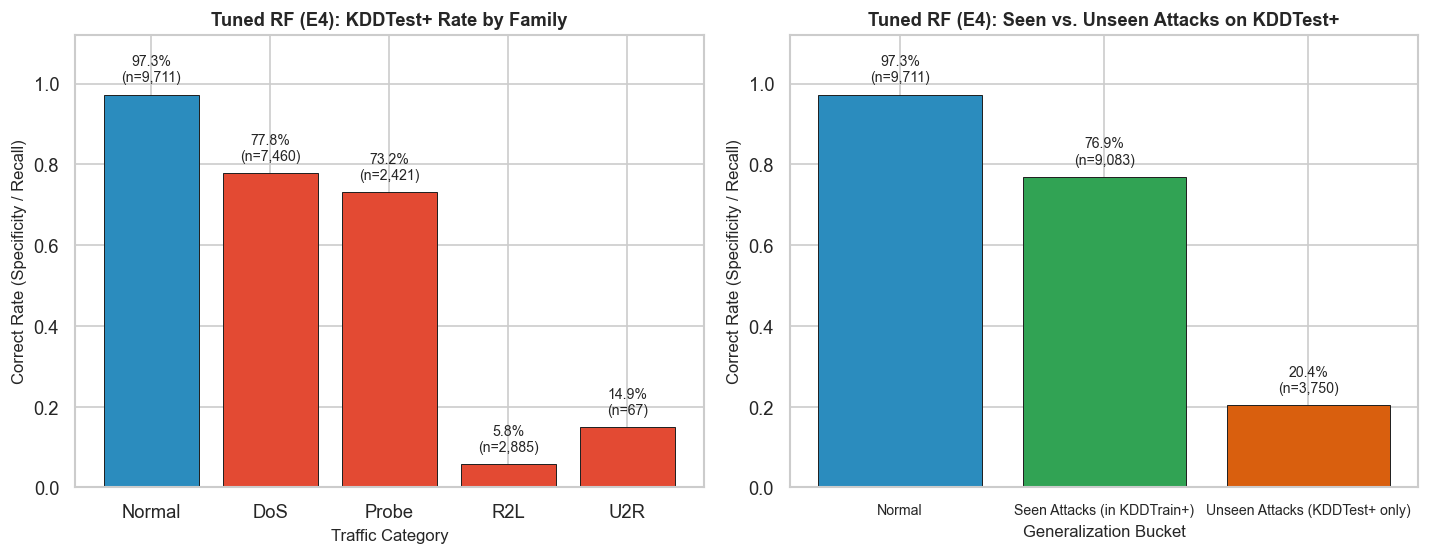

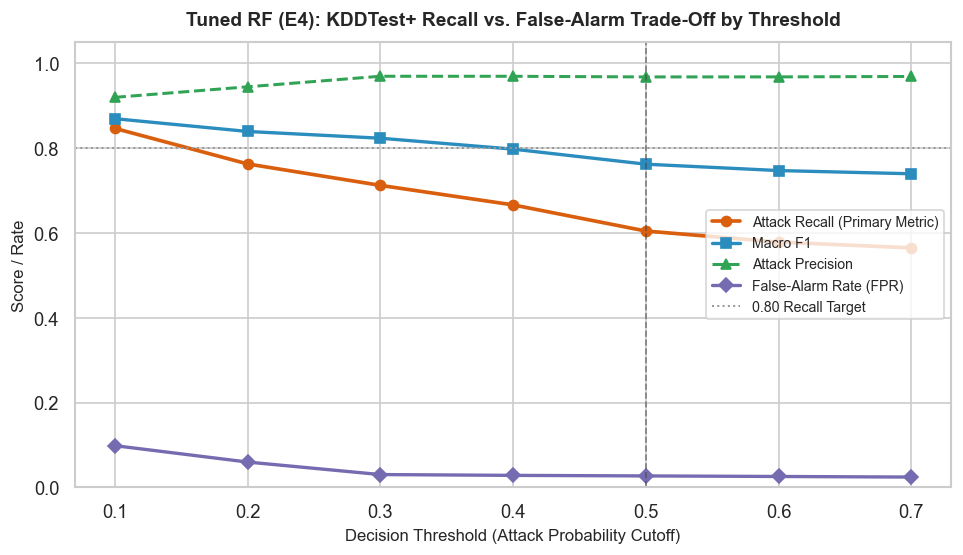

In [8]:
fig3 = plot_test_error_breakdown(family_df, seen_unseen_df, model_label="Tuned RF (E4)")
plt.show()
plt.close(fig3)

fig4 = plot_threshold_tradeoff(threshold_df, model_label="Tuned RF (E4)")
plt.show()
plt.close(fig4)

## 5. Honest Verdict Against Proposal Success Criteria & Saved Model Check

1. **Criterion 1 — Test Attack Recall `>= 0.80`:** **Not met at the default `0.50` threshold** (`0.6038`). Error analysis confirms that **17 unseen attack types** (`3,750` test rows, `29.2%` of all test attacks) receive only `20.40%` recall and stealthy R2L/U2R attacks receive `5.82%` / `14.93%` recall at `0.50`. However, E4 achieves a strong **`0.9652` ROC-AUC** on `KDDTest+` (vs. `0.7975` for E1), so lowering the triage threshold to `0.10` lifts attack recall to **`0.8460`** (`macro F1 = 0.8688`) at `9.84%` FPR — directly demonstrating why Stage 3's Streamlit prototype exposes an interactive threshold slider.
2. **Criterion 2 — Macro F1 Gain `>= +0.02` over Baseline (E1):** **Met on validation** (`+0.0273`, `0.9717 → 0.9990`), and **partially met on `KDDTest+` at default `0.50`** (`+0.0080`, `0.7535 → 0.7615`), where E4 cuts false alarms by **63.6%** (`723 → 263`) and increases attack precision from `91.72%` to `96.72%`.

In [9]:
# Verify compressed model artifact produced by `python -m src.train`
assert DEFAULT_MODEL_PATH.exists(), f"Expected saved model at {DEFAULT_MODEL_PATH}"
size_mb = DEFAULT_MODEL_PATH.stat().st_size / (1024 * 1024)
loaded_model = joblib.load(DEFAULT_MODEL_PATH)
sample_probs = loaded_model.predict_proba(X_test.head(5))[:, 1]
print(f"Verified saved artifact: {DEFAULT_MODEL_PATH.name} ({size_mb:.2f} MB < 50 MB limit)")
print("Sample attack probabilities on first 5 KDDTest+ rows:", [round(float(p), 4) for p in sample_probs])

Verified saved artifact: model.joblib (3.58 MB < 50 MB limit)
Sample attack probabilities on first 5 KDDTest+ rows: [1.0, 1.0, 0.0017, 0.9425, 0.3455]
